# Granovetter Threshold Model — Targeting for Maximum Spread

## 1. Setup

In [53]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import random
from time import time
import os
import multiprocessing as mp
from tqdm.auto import tqdm

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = False
plt.rcParams["figure.dpi"] = 120

print("Packages loaded (with multiprocessing and tqdm).")

Packages loaded (with multiprocessing and tqdm).


## 2. Configuration

In [54]:
# Parameters
#we derive N and k_avg from the Hamsterster network

B = 5  # Number of initial adopters
F0_VALUES = [0.01, 0.02, 0.05, 0.10]     # seed fractions for the f0-sweep (Step 3)
F0_MAIN = 0.05                           # fixed seed fraction for strategy comparison
RUNS_PER_SETTING = 5                    # number of Monte Carlo simulation runs (20-50)

# Threshold mode, defines how the threshold is set for each node
#THRESHOLD_MODE = 'beta'   # 'uniform', 'beta', 'constant', 'normal'
TAU_SWEEP = np.arange(0.05, 0.51, 0.05)  # tau values 0.05 ... 0.50 for the tau-sweep
TAU_MAIN = 0.20                          # fixed intermediate tau for f0-sweep
PHI_MEAN = 0.30
PHI_STD = 0.10

# Maximum number of steps in each simulation run
MAX_STEPS = 200                         #t_max 

print(f"f0 values: {F0_VALUES}, main f0: {F0_MAIN}, runs per setting: {RUNS_PER_SETTING}")

f0 values: [0.01, 0.02, 0.05, 0.1], main f0: 0.05, runs per setting: 5


## 3. Network

In [55]:
# Load the Hamsterster network 
FILEPATH = "datasets/petster-hamster.edges"
df = pd.read_csv(FILEPATH, comment="%", header=None,names=["source_profile", "dest_profile"])
df = df[df["source_profile"] != df["dest_profile"]]
G_full = nx.from_pandas_edgelist(df, "source_profile", "dest_profile")      #graph of full network (2426 nodes)
largest_cc = max(nx.connected_components(G_full), key=len)              
G = G_full.subgraph(largest_cc).copy()                                      #graph of LCC (2000 nodes)

# Structural dimensions LCC Hamsterster network
N = G.number_of_nodes()
M = G.number_of_edges()
k_avg = 2 * M / N
print(f"LCC: N={N}, M={M}, <k>={k_avg:.2f}")


LCC: N=2000, M=16098, <k>=16.10


## 4. Threshold Distributions

In [56]:
def draw_thresholds(G, mode='uniform', phi_mean=0.3, phi_std=0.1):
    """
        This function draws threshold values for each node in the graph G.
        The threshold mode determines how the threshold values are generated.
        Each node samples a threshold value from a specified distribution (defined by mode).
        The phi_mean and phi_std parameters are used to control the mean and standard deviation of the normal distribution.
    """
    if mode == 'uniform':
        return {n: np.random.uniform(0, 1) for n in G}
    if mode == 'beta':
        a, b = 2, 5
        return {n: np.random.beta(a, b) for n in G}
    if mode == 'constant':
        return {n: float(phi_mean) for n in G}
    if mode == 'normal':
        vals = np.clip(np.random.normal(phi_mean, phi_std, len(G)), 0, 1)
        return {n: float(vals[i]) for i, n in enumerate(G)}
    raise ValueError(f"Unknown threshold mode: {mode}")

# This loop iterates over each graph in the graphs dictionary
# For each graph, it draws threshold values using the draw_thresholds function
# It then calculates the mean of these threshold values and prints it
#for name, G in graphs.items():
#    th = draw_thresholds(G, mode=THRESHOLD_MODE, phi_mean=PHI_MEAN, phi_std=PHI_STD)
#    arr = np.array(list(th.values()))
#    print(name, "threshold mean:", round(arr.mean(), 3))


## 5. Threshold Dynamics

In [57]:
def threshold_dynamics(G, seeds, thresholds, max_steps=100):
    """
        This function simulates the threshold dynamics on a graph G
        The function takes as input the graph G, a list of seed nodes (seeds), a dictionary of threshold values (thresholds), and the maximum number of steps (max_steps)
        The function returns a dictionary of adopted nodes (adopted) and a numpy array of the fraction of adopted nodes over time (history)
    """
    adopted = {n: 0 for n in G}
    for s in seeds:
        adopted[s] = 1 # initially, all seed nodes are adopted

    history = [sum(adopted.values()) / len(G)] #the history will store the fraction of adopted nodes over time, initially it is the fraction of adopted seed nodes

    for _ in range(max_steps): # iterate max_steps times
        new_adopted = adopted.copy()
        changed = False
        for i in G: # iterate over all nodes i in the graph G
            if adopted[i] == 0: # if node i is not adopted yet
                neigh = list(G.neighbors(i))
                if not neigh: # if node i has no neighbors, skip it
                    continue
                frac = sum(adopted[j] for j in neigh) / len(neigh) # calculate the fraction of adopted neighbors of node i
                if frac >= thresholds[i]: # if the fraction of adopted neighbors is greater than or equal to the threshold of node i
                    new_adopted[i] = 1 # adopt node i
                    changed = True
        #-- end of one iteration

        # update the adopted nodes after checking all nodes
        adopted = new_adopted
        history.append(sum(adopted.values()) / len(G)) #add the total adopted this timestep to the history
        if not changed:
            break # if no node is adopted in this iteration, break the loop (no more adoptions so we can stop)

    return adopted, np.array(history)


## 6. Measurement Utilities

In [58]:

def final_adoption_fraction(adopted):
    return sum(adopted.values()) / len(adopted)

# function to calculate the time to reach a target fraction of adopted nodes
def time_to_fraction(history, target=0.5):
    idx = np.where(history >= target)[0]
    return float(idx[0]) if len(idx) else np.nan


## 7. Seeding Strategies — Heuristics

In [59]:

def random_seeds(G, B):
    return random.sample(list(G.nodes()), B)

def high_degree_seeds(G, B):
    """
    Select the top-B nodes with the highest degree in graph G.
    """
    # Get all (node, degree) pairs
    degree_list = list(G.degree())

    # Sort nodes by degree in descending order
    sorted_by_degree = sorted(degree_list, key=lambda x: x[1], reverse=True)

    # Take the top-B entries
    top_B = sorted_by_degree[:B]

    # Extract only the node IDs
    result = []
    for n, d in top_B:
        result.append(n)

    return result

#This code below does the same as for degree. It uses a list comprehension and a lambda function.
# The lambda function takes a tuple x = (n, b) and returns the second element (b), which is the betweenness centrality of node n.]
# sorted(bc.items(), key=lambda x: x[1], reverse=True) sorts the items of the dictionary bc.items() by the value of the betweenness centrality (x[1]) in descending order. (Highest first)
# [:B] takes the first B entries from the sorted list, which are the nodes with the highest betweenness centrality.
def betweenness_seeds(G, B):
    bc = nx.betweenness_centrality(G) #returns a dictionary that maps each node to its betweenness centrality. {n_1: bc(n_1), n_2: bc(n_2), ...}
    return [n for n, _ in sorted(bc.items(), key=lambda x: x[1], reverse=True)[:B]]


# This function seeds the network with B nodes with the highest core number, the core number is the number of nodes that are connected to all its neighbors
# For a given graph G, the core number of a node v is the largest integer k such that v belongs to the k-core of G.
# In other words:
# 	•	It tells you how deeply embedded a node is within the dense core structure of the network.
# 	•	A higher core number means the node is part of a more cohesive and connected region of the graph.
def kcore_seeds(G, B):
    core = nx.core_number(G) #core_number is a dictionary that maps each node to its core number. 
    return [n for n, _ in sorted(core.items(), key=lambda x: x[1], reverse=True)[:B]]

## 8. Spread Estimation

In [60]:
# This function estimates the spread of the threshold dynamics on graph G
# It runs the threshold dynamics R times with different random seeds and thresholds
# and returns the average final adoption fraction
def estimate_spread(G, seeds, thresholds, R=5, max_steps=100):
    results = []
    for _ in range(R):
        adopted, _ = threshold_dynamics(G, seeds, thresholds, max_steps=max_steps)
        results.append(final_adoption_fraction(adopted))
    return float(np.mean(results))


## 9 Experiment Runner (for empirical network)

In [61]:

def run_experiments(G, 
                    runs_per_setting=10, 
                    threshold_mode='constant',
                    tau=0.20,
                    phi_mean=0.3, 
                    phi_std=0.1, 
                    B=5, 
                    max_steps=200):
    import numpy as _np
    import pandas as _pd
    from time import time as _time
    results = []
    t0 = _time()

    if threshold_mode == "constant":
        thresholds = {n: tau for n in G}
    else:
        thresholds = draw_thresholds(
            G,
            mode=threshold_mode,
            phi_mean=phi_mean,
            phi_std=phi_std)

    strategies = { #dictionary of seed selection strategies, the value is a (lamba) function that returns the seed set for the current strategy
        'Random': lambda: random_seeds(G, B),
        'Degree': lambda: high_degree_seeds(G, B),
        'Betweenness': lambda: betweenness_seeds(G, B)}

    for strat, seed_fn in strategies.items(): # for each seed selection strategy
        seeds = seed_fn() # get the seed set for the current strategy
        final_sizes, t50_list = [], []
        for _ in range(runs_per_setting):
            adopted, history = threshold_dynamics(G, seeds, thresholds, max_steps=max_steps)
            final_sizes.append(final_adoption_fraction(adopted))
            t50_list.append(time_to_fraction(history, target=0.5))
        results.append({
            'Strategy': strat,
            'FinalAdoption': float(_np.mean(final_sizes)),
            'CascadeProb': float(_np.mean(_np.array(final_sizes) >= 0.5)),
            'Time50': float(_np.nanmean(t50_list)),
            'Efficiency': float(_np.mean(final_sizes) / B),
            'Seeds': seeds
        })
    t1 = _time()
    print(f"Completed {len(strategies)} strategies in {t1 - t0:.1f}s")
    return _pd.DataFrame(results)


## 10. Run the full experiment

In [62]:
df_results = run_experiments(
    G=G,
    runs_per_setting=RUNS_PER_SETTING,
    threshold_mode="constant",
    tau=TAU_MAIN,
    B=B,
    max_steps=MAX_STEPS
)

df_results

C:\Users\nckro\AppData\Local\Temp\ipykernel_43520\294141422.py:40: RuntimeWarning: Mean of empty slice
  'Time50': float(_np.nanmean(t50_list)),


Completed 3 strategies in 11.2s


,Strategy,FinalAdoption,CascadeProb,Time50,Efficiency,Seeds
0,Random,0.0055,0.0,NaN,0.0011,"[1906, 94, 384, 1701, 827]"
1,Degree,0.9730,1.0,8.0,0.1946,"[237, 238, 44, 168, 169]"
2,Betweenness,0.9730,1.0,9.0,0.1946,"[237, 169, 137, 238, 251]"


## 11. Save results to CSV

In [63]:

csv_path = "granovetter_experiment_results.csv"
df_results.to_csv(csv_path, index=False)
print("Saved:", csv_path)

Saved: granovetter_experiment_results.csv


## 12. Summaries and Tables

In [64]:
pivot_final = df_results.pivot_table(index='Strategy', values='FinalAdoption', aggfunc='mean')
pivot_cascade = df_results.pivot_table(index='Strategy', values='CascadeProb', aggfunc='mean')
pivot_eff = df_results.pivot_table(index='Strategy', values='Efficiency', aggfunc='mean')
pivot_time = df_results.pivot_table(index='Strategy', values='Time50', aggfunc='mean')

print("Final adoption (mean):")
display(pivot_final)
print("\nCascade probability (mean):")
display(pivot_cascade)
print("\nEfficiency (mean):")
display(pivot_eff)
print("\nTime to half adoption:")
display(pivot_time)

Final adoption (mean):


,FinalAdoption
Strategy,
Betweenness,0.9730
Degree,0.9730
Random,0.0055



Cascade probability (mean):


,CascadeProb
Strategy,
Betweenness,1.0
Degree,1.0
Random,0.0



Efficiency (mean):


,Efficiency
Strategy,
Betweenness,0.1946
Degree,0.1946
Random,0.0011



Time to half adoption:


,Time50
Strategy,
Betweenness,9.0
Degree,8.0


## 13. Sweeps

adjusted from '5. Parameter Sensitivity: Sweeping β' as defined in Network_Topology_Spreading_Experiment.ipyb 

Tau sweep:   0%|          | 0/10 [00:00<?, ?it/s]

Completed 3 strategies in 10.8s
Completed 3 strategies in 10.8s
Completed 3 strategies in 11.0s


C:\Users\nckro\AppData\Local\Temp\ipykernel_43520\294141422.py:40: RuntimeWarning: Mean of empty slice
  'Time50': float(_np.nanmean(t50_list)),


Completed 3 strategies in 10.8s
Completed 3 strategies in 10.8s
Completed 3 strategies in 10.8s
Completed 3 strategies in 10.7s
Completed 3 strategies in 10.7s
Completed 3 strategies in 13.6s
Completed 3 strategies in 20.9s


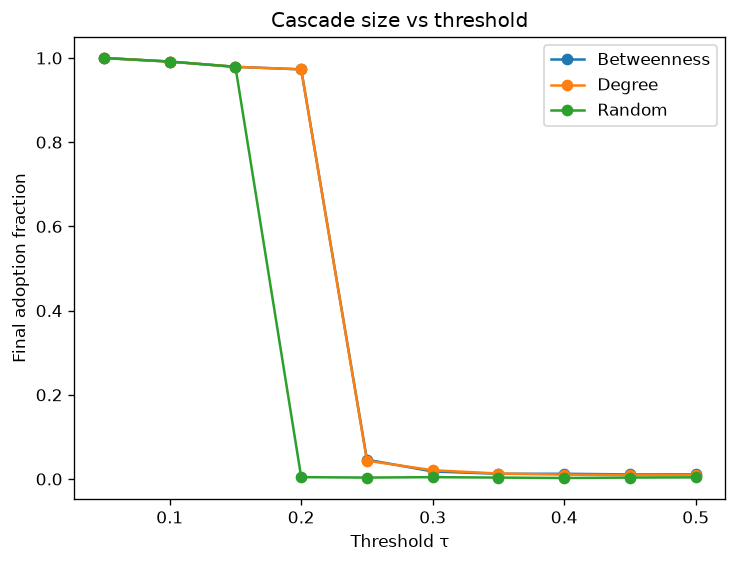

f0 sweep:   0%|          | 0/4 [00:00<?, ?it/s]

Completed 3 strategies in 18.4s
Completed 3 strategies in 17.9s
Completed 3 strategies in 13.5s
Completed 3 strategies in 10.6s


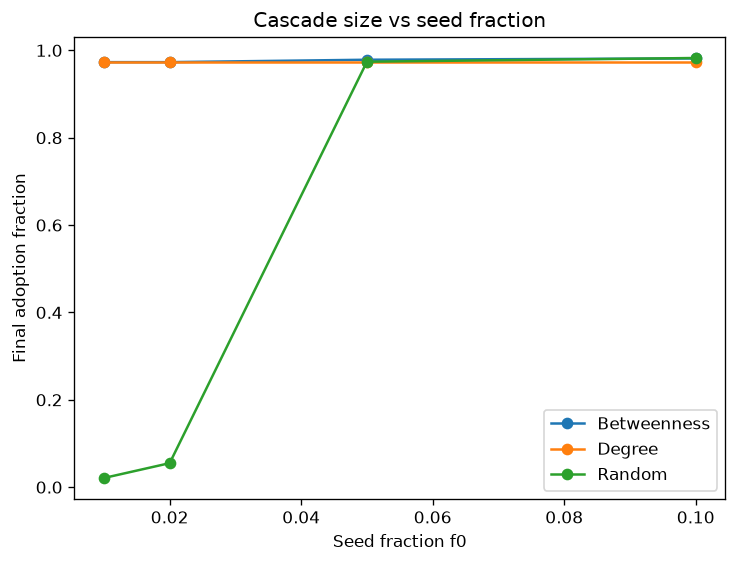

In [65]:
def sweep_tau(G, tau_values, runs=10):
    dfs = []
    for tau in tqdm(tau_values, desc="Tau sweep"):
        df = run_experiments(G=G,runs_per_setting=runs,threshold_mode="constant",tau=tau,B=B,max_steps=MAX_STEPS)
        df["tau"] = tau
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

df_tau = sweep_tau(G, TAU_SWEEP, runs=RUNS_PER_SETTING)

plt.figure(figsize=(7,5))
for strategy, group in df_tau.groupby("Strategy"):
    means = group.groupby("tau")["FinalAdoption"].mean()
    plt.plot(
        means.index,
        means.values,
        marker="o",
        label=strategy
    )
plt.xlabel("Threshold τ")
plt.ylabel("Final adoption fraction")
plt.title("Cascade size vs threshold")
plt.legend()
plt.show()

def sweep_f0(G, f0_values, tau=TAU_MAIN):
    dfs = []
    for f0 in tqdm(f0_values, desc="f0 sweep"):
        B_current = int(f0 * G.number_of_nodes())
        df = run_experiments(G=G,runs_per_setting=RUNS_PER_SETTING,threshold_mode="constant",tau=tau,B=B_current,max_steps=MAX_STEPS)
        df["f0"] = f0
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

df_f0 = sweep_f0(G,F0_VALUES)

plt.figure(figsize=(7,5))
for strategy, group in df_f0.groupby("Strategy"):
    means = group.groupby("f0")["FinalAdoption"].mean()
    plt.plot(
        means.index,
        means.values,
        marker="o",
        label=strategy
    )
plt.xlabel("Seed fraction f0")
plt.ylabel("Final adoption fraction")
plt.title("Cascade size vs seed fraction")
plt.legend()
plt.show()

## 14. Visual Comparison (original)

<Figure size 840x480 with 0 Axes>

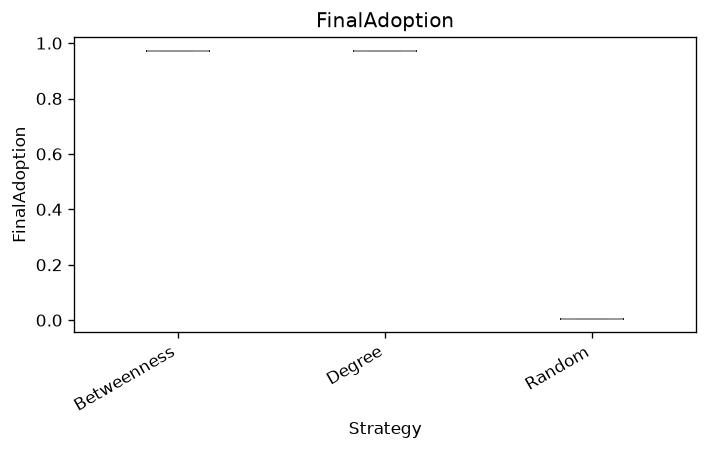

<Figure size 840x480 with 0 Axes>

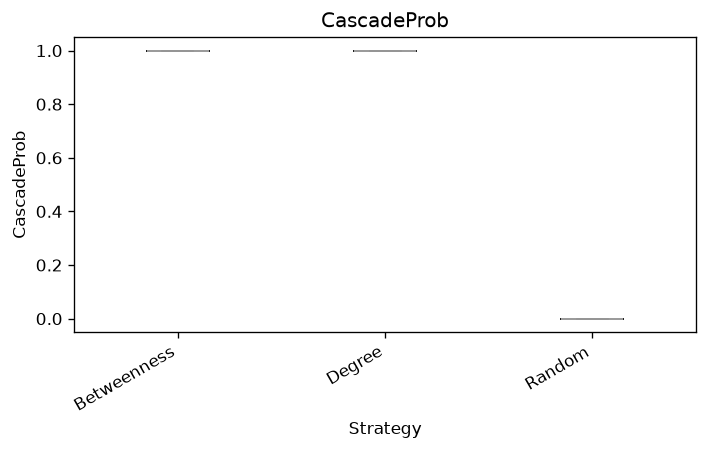

<Figure size 840x480 with 0 Axes>

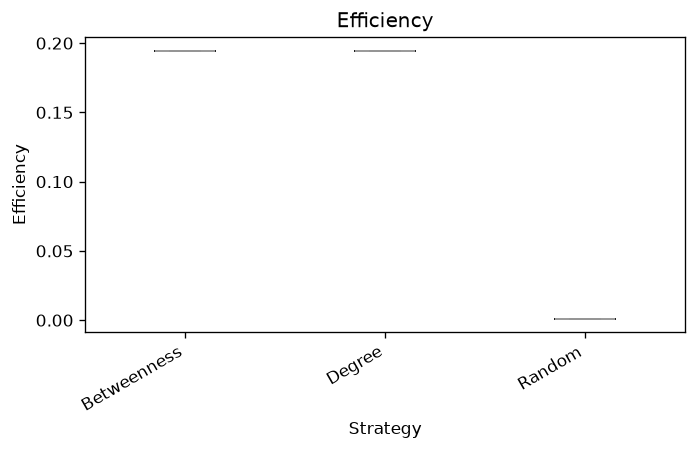

In [66]:

# Separate charts per metric, no seaborn and no explicit colors
metrics = ['FinalAdoption', 'CascadeProb', 'Efficiency']
for metric in metrics:
    plt.figure(figsize=(7,4))
    df_results.boxplot(column=metric, by='Strategy', grid=False)
    plt.title(metric)
    plt.suptitle("")
    plt.xlabel("Strategy")
    plt.ylabel(metric)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()
